## Importation des librairies 


In [991]:
#Analyse de données

import pandas as pd
import numpy as np

#Visualisation de données

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#Préparation de données pour le machine learning

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modélisation et évaluation

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV

from sklearn.metrics import mean_absolute_error, mean_squared_error

## EDA


In [992]:
# Chargement et visualisation des données 

df = pd.read_csv('Walmart_Store_sales.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.045,214.777523,6.858
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.435,128.616064,7.470
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.719581,5.936
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.556497,7.346
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.759,212.412888,7.092


In [993]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         150 non-null    float64
 1   Date          132 non-null    str    
 2   Weekly_Sales  136 non-null    float64
 3   Holiday_Flag  138 non-null    float64
 4   Temperature   132 non-null    float64
 5   Fuel_Price    136 non-null    float64
 6   CPI           138 non-null    float64
 7   Unemployment  135 non-null    float64
dtypes: float64(7), str(1)
memory usage: 9.5 KB


In [994]:
df.describe(include='all')

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.000000,132,1.360000e+02,138.000000,132.000000,136.000000,138.000000,135.000000
unique,NaN,85,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,07-01-2011,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN
mean,9.866667,NaN,1.249536e+06,0.079710,61.398106,3.320853,179.898509,7.598430
std,6.231191,NaN,6.474630e+05,0.271831,18.378901,0.478149,40.274956,1.577173
min,1.000000,NaN,2.689290e+05,0.000000,18.790000,2.514000,126.111903,5.143000
25%,4.000000,NaN,6.050757e+05,0.000000,45.587500,2.852250,131.970831,6.597500
50%,9.000000,NaN,1.261424e+06,0.000000,62.985000,3.451000,197.908893,7.470000
75%,15.750000,NaN,1.806386e+06,0.000000,76.345000,3.706250,214.934616,8.150000


In [995]:
# Doublons

print(f"Le dataset contient {df.duplicated().sum()} doublons.")

Le dataset contient 0 doublons.


In [996]:
#Valeurs manquantes

total_missing = df.isna().sum().sum()
overall_pct = total_missing / df.size * 100
print(df.isna().sum().sort_values())
print(f"Pourcentage de valeurs manquantes : {overall_pct:.2f}%")

Store            0
Holiday_Flag    12
CPI             12
Weekly_Sales    14
Fuel_Price      14
Unemployment    15
Date            18
Temperature     18
dtype: int64
Pourcentage de valeurs manquantes : 8.58%


In [997]:
# Suppression des lignes avec des valeurs manquantes pour la variable cible weekly_sales

df.dropna(subset=['Weekly_Sales'], inplace=True)

In [998]:
# Modification de la colonne 'Date'

# Conversion la colonne Date en datetime

df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# Création des nouvelles colonnes

df['Day'] = df['Date'].dt.day
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['Day_of_Week'] = df['Date'].dt.dayofweek

print(df.head())

   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0    6.0 2011-02-18    1572117.54           NaN        59.61       3.045   
1   13.0 2011-03-25    1807545.43           0.0        42.38       3.435   
3   11.0        NaT    1244390.03           0.0        84.57         NaN   
4    6.0 2010-05-28    1644470.66           0.0        78.89       2.759   
5    4.0 2010-05-28    1857533.70           0.0          NaN       2.756   

          CPI  Unemployment   Day  Month    Year  Day_of_Week  
0  214.777523         6.858  18.0    2.0  2011.0          4.0  
1  128.616064         7.470  25.0    3.0  2011.0          4.0  
3  214.556497         7.346   NaN    NaN     NaN          NaN  
4  212.412888         7.092  28.0    5.0  2010.0          4.0  
5  126.160226         7.896  28.0    5.0  2010.0          4.0  


In [999]:
# Vérification des écarts de dates pour chaque magasin pour l'éventuelle imputation des valeurs manquantes

df = df.sort_values(['Store', 'Date']).reset_index(drop=True)

df['date_diff'] = df.groupby('Store')['Date'].diff().dt.days

print(df[df['date_diff'] > 7][['Store', 'Date', 'date_diff']])

# Vérification des périodes de dates pour chaque magasin pour l'éventuelle imputation des valeurs manquantes

df.groupby('Store')['Date'].agg(['min', 'max', 'count'])




     Store       Date  date_diff
1      1.0 2010-05-14       91.0
2      1.0 2010-08-27      105.0
3      1.0 2011-05-27      273.0
4      1.0 2011-08-05       70.0
5      1.0 2011-11-18      105.0
..     ...        ...        ...
129   19.0 2012-05-04       14.0
130   19.0 2012-06-22       49.0
132   20.0 2010-09-24       91.0
133   20.0 2010-12-31       98.0
134   20.0 2012-02-03      399.0

[95 rows x 3 columns]


,min,max,count
Store,,,
1.0,2010-02-12,2012-10-19,8
2.0,2010-02-19,2012-02-24,6
3.0,2010-02-05,2012-10-19,10
4.0,2010-05-28,2011-12-16,6
5.0,2010-04-30,2012-10-19,7
6.0,2010-04-30,2011-08-26,6
7.0,2010-04-02,2012-09-07,7
8.0,2010-02-12,2011-08-19,6
9.0,2010-06-18,2010-11-19,4


In [1000]:
# Suppression des lignes avec des valeurs manquantes pour la variable "Date"

df = df.dropna(subset=["Date"])


Les lignes dont la date est manquante ont été supprimées plutôt qu’imputées, car la structure temporelle du jeu de données ne permet pas de déterminer les dates avec suffisamment de fiabilité. Les différents magasins ne couvrent pas les mêmes périodes : leurs dates minimales et maximales varient fortement, et certains ne disposent que de quelques observations. De plus, les écarts entre deux observations peuvent atteindre plusieurs semaines ou plusieurs mois. Imputer une date en supposant une fréquence hebdomadaire régulière pourrait donc créer artificiellement des observations et, surtout, attribuer une saison ou une période incorrecte à certaines données. La suppression des lignes dont la date est inconnue permet ainsi de préserver l'intégrité temporelle du jeu de données et d'éviter d'introduire des hypothèses non vérifiables.

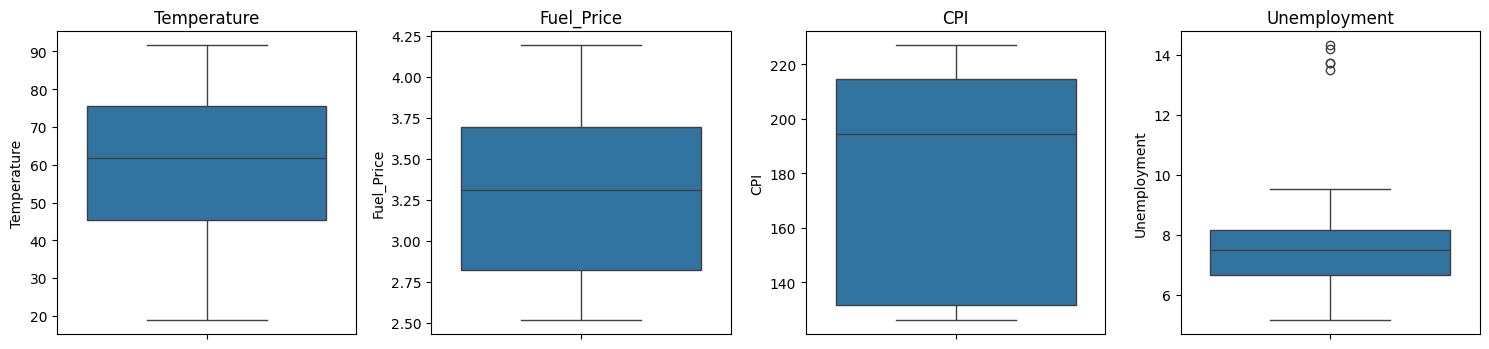

In [1001]:
#Détection des valeurs abérantes

numeric_cols = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

plt.figure(figsize=(15, 10))

#Boucle sur chaque variable numérique et création des boxplots

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [1002]:
# Détection des valeurs aberrantes avec la méthode de l'IQR

# Boucle sur chaque variable numérique

for col in numeric_cols:
    
    # Calcul du premier quartile (Q1 : 25 % des données)
    
    Q1 = df[col].quantile(0.25)
    
    # Calcul du troisième quartile (Q3 : 75 % des données)
    
    Q3 = df[col].quantile(0.75)
    
    # Calcul de l'écart interquartile (IQR) : dispersion des 50 % des données centrales
    
    IQR = Q3 - Q1

    # Définition des bornes inférieure et supérieure selon la règle de 1,5 × IQR
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Identification des valeurs aberrantes en dehors des bornes définies

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    # Affichage du nombre de valeurs aberrantes détectées pour chaque variable
    
    print(f"{col}: {len(outliers)} outlier(s)")

Temperature: 0 outlier(s)
Fuel_Price: 0 outlier(s)
CPI: 0 outlier(s)
Unemployment: 5 outlier(s)


La variable unemployement contient 5 valeurs abérantes.

In [1003]:
# Suppression des valeurs aberrantes du DataFrame

print("Nombre de lignes avant :", len(df))

df = df.drop(outliers.index)

print("Nombre de lignes après :", len(df))


Nombre de lignes avant : 118
Nombre de lignes après : 113


In [1004]:
# Revérification des valeurs manquantes après suppression des lignes avec des valeurs manquantes

total_missing = df.isna().sum().sum()
overall_pct = total_missing / df.size * 100
print(df.isna().sum().sort_values())
print(f"Pourcentage de valeurs manquantes : {overall_pct:.2f}%")

Store            0
Date             0
Weekly_Sales     0
Day              0
Day_of_Week      0
Year             0
Month            0
Holiday_Flag     9
CPI              9
Temperature     10
Unemployment    11
Fuel_Price      11
date_diff       19
dtype: int64
Pourcentage de valeurs manquantes : 4.70%


# Analyse univariée

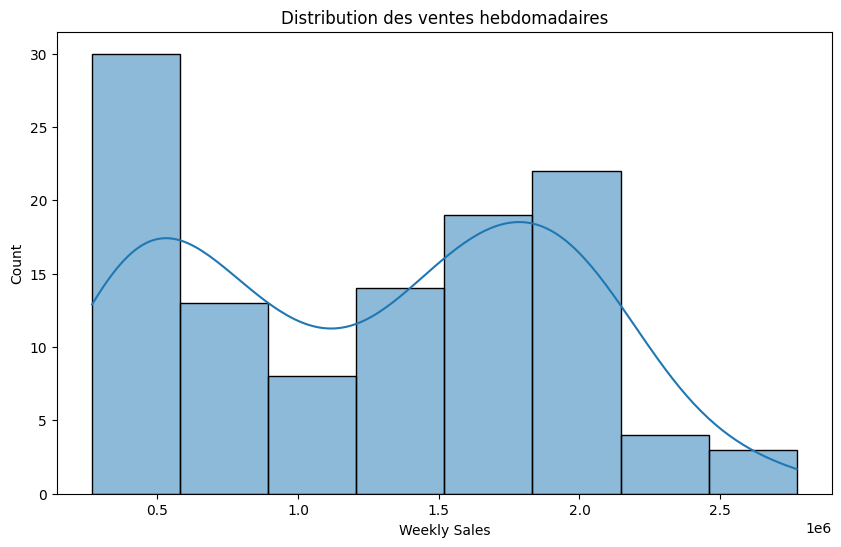

In [1005]:
# Visualisation de la distribution des ventes hebdomadaires

plt.figure(figsize=(10, 6))
sns.histplot(df['Weekly_Sales'], kde=True)
plt.title('Distribution des ventes hebdomadaires')
plt.xlabel('Weekly Sales')
plt.show()


L'histogramme des ventes hebdomadaires met en évidence une distribution hétérogène avec deux pics autour de 0,5 million et de 1,8 million de dollars. Cette dispersion peut s'expliquer par les différences de performance entre les magasins et par les caractéristiques propres à chaque période.

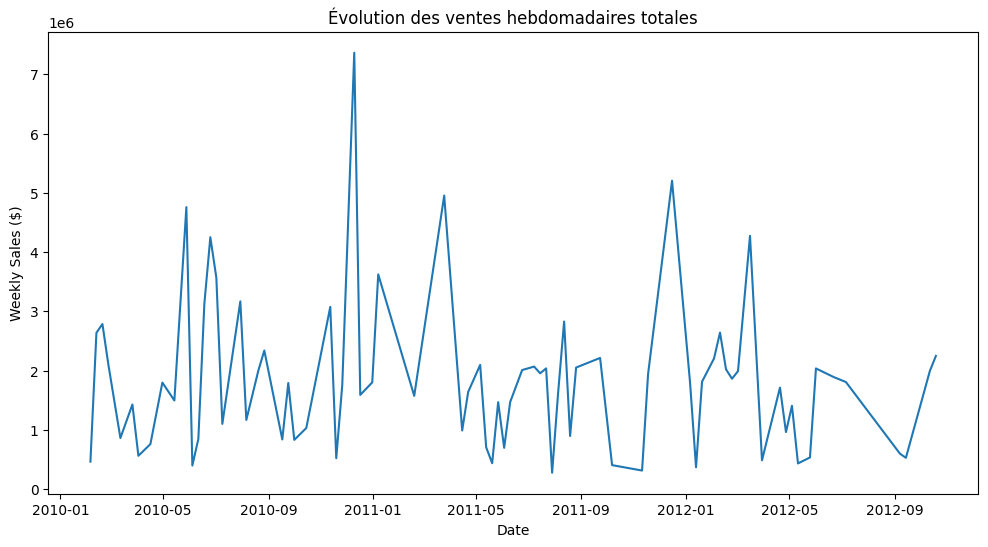

In [1006]:
# Visualisation de l'évolution des ventes hebdomadaires totales au fil du temps


df["Date"] = pd.to_datetime(df["Date"])

weekly_sales = (
    df.groupby("Date")["Weekly_Sales"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title("Évolution des ventes hebdomadaires totales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales ($)")
plt.show()


L'évolution des ventes hebdomadaires totales entre 2010 et 2012 révèle une forte volatilité des ventes. Aucune tendance générale clairement croissante ou décroissante n'est observée. Plusieurs pics importants sont néanmoins visibles, dont un maximum d'environ 7,3 millions de dollars vers la fin de l'année 2010. Ces variations pourraient être liées à la saisonnalité, aux périodes de fêtes ou à des événements commerciaux particuliers.

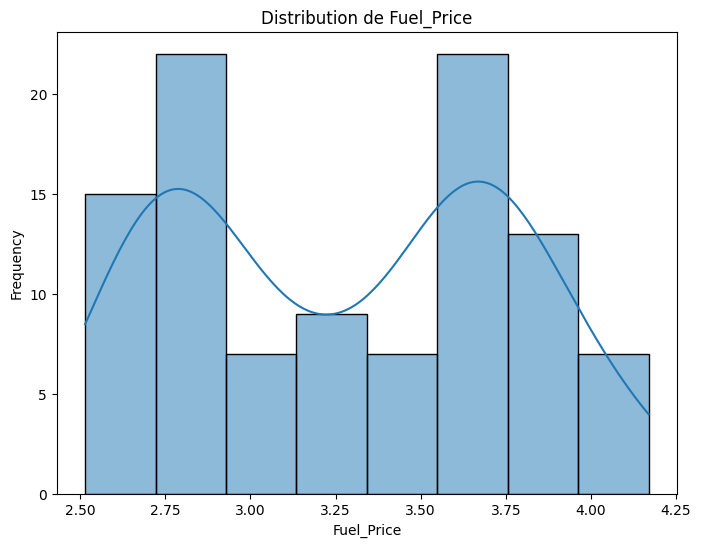

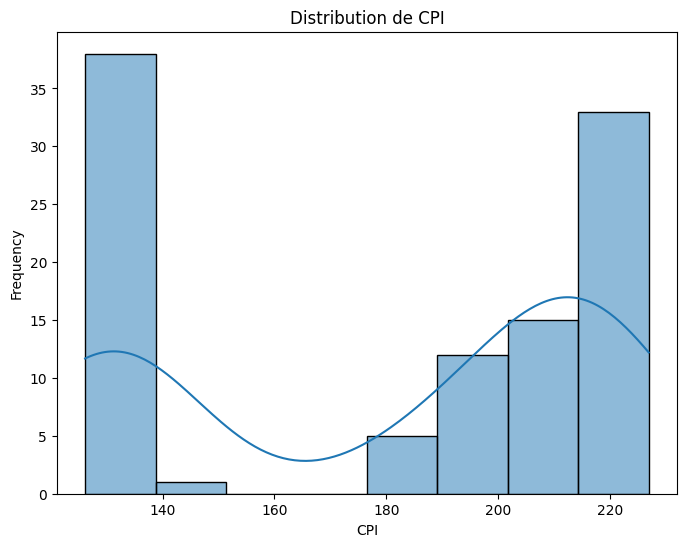

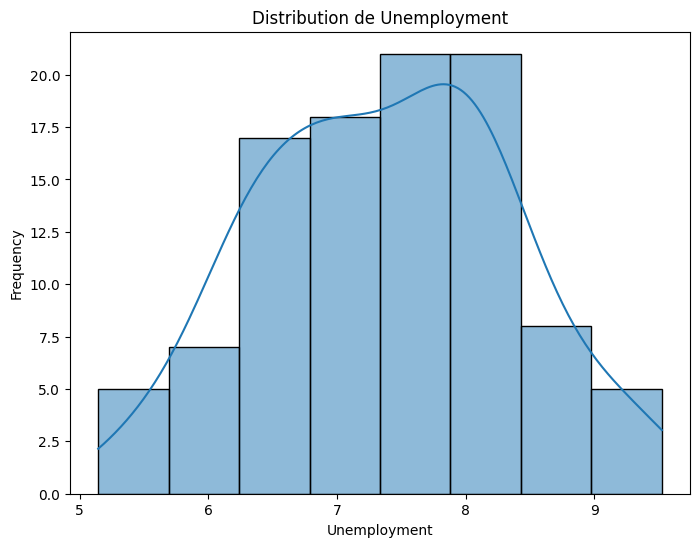

In [1007]:
# Distribution des variables 'fuel_price', 'CPI' et 'Unemployment'

columns_to_plot = ['Fuel_Price', 'CPI', 'Unemployment']

for col in columns_to_plot:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution de {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

    

Fuel_Price et CPI présentent des distributions bimodales, ce qui peut indiquer la présence de deux groupes ou de deux périodes économiques distinctes dans les données. À l’inverse, Unemployment est davantage concentré autour de 7–8 %, avec une distribution plus régulière et proche d’une forme normale. Ces différences montrent que les trois variables n'ont pas le même comportement statistique et qu’il serait pertinent d’étudier leur évolution dans le temps ainsi que leurs éventuelles relations entre elles.

# Analyse bivariée

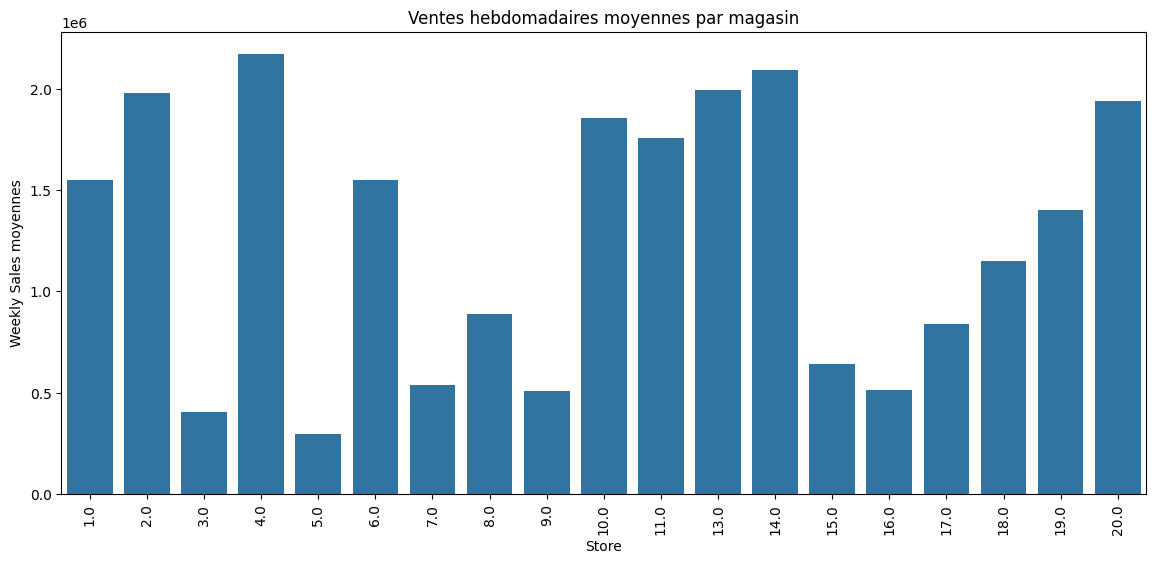

In [1008]:
# Visualisation des ventes hebdomadaires moyennes par magasin

store_sales = df.groupby('Store')['Weekly_Sales'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=store_sales.index, y=store_sales.values)
plt.title('Ventes hebdomadaires moyennes par magasin')
plt.xlabel('Store')
plt.ylabel('Weekly Sales moyennes')
plt.xticks(rotation=90)

# Valeurs en millions
labels = [f'{value/1_000_000:.2f}M' for value in store_sales.values]
plt.show()


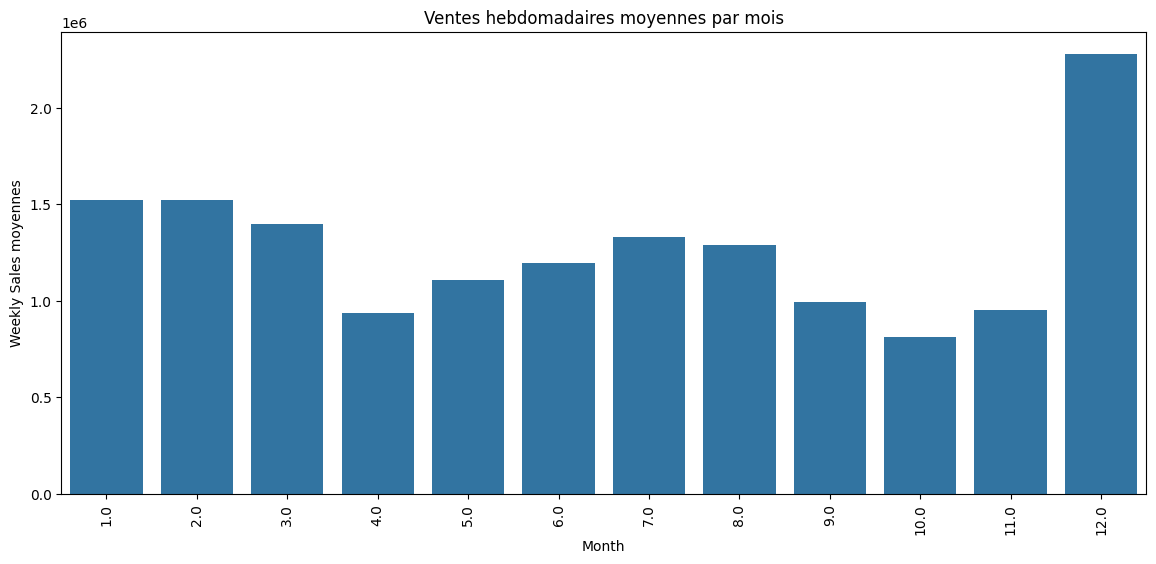

In [1009]:
# Visualisation des ventes hebdomadaires totales moyennes par mois

store_sales = df.groupby('Month')['Weekly_Sales'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=store_sales.index, y=store_sales.values)
plt.title('Ventes hebdomadaires moyennes par mois')
plt.xlabel('Month')
plt.ylabel('Weekly Sales moyennes')
plt.xticks(rotation=90)
plt.show()

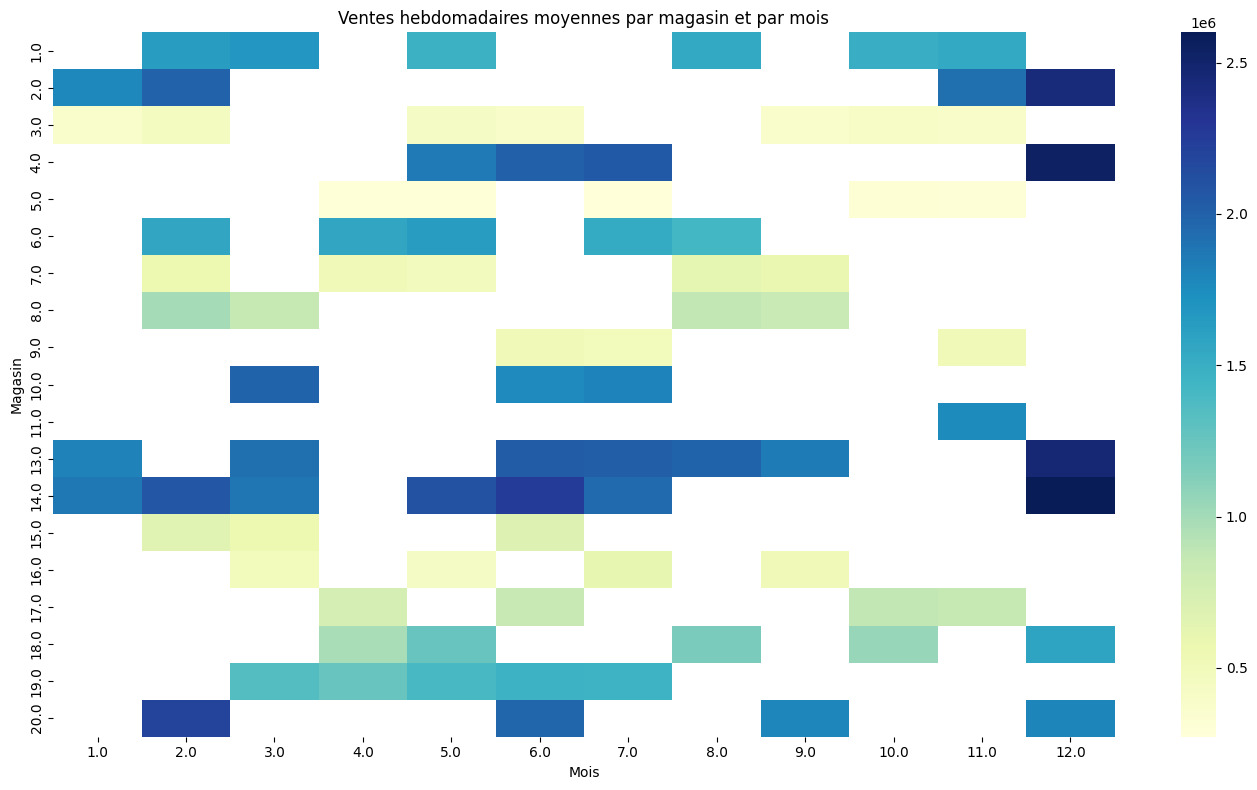

In [1010]:
# Visualisation des ventes hebdomadaires moyennes par magasin et par mois

sales_store_month = df.pivot_table(
    values='Weekly_Sales',
    index='Store',
    columns='Month',
    aggfunc='mean'
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    sales_store_month,
    cmap='YlGnBu',
    annot=False,
    fmt='.0f'
)

plt.title('Ventes hebdomadaires moyennes par magasin et par mois')
plt.xlabel('Mois')
plt.ylabel('Magasin')
plt.tight_layout()
plt.show()


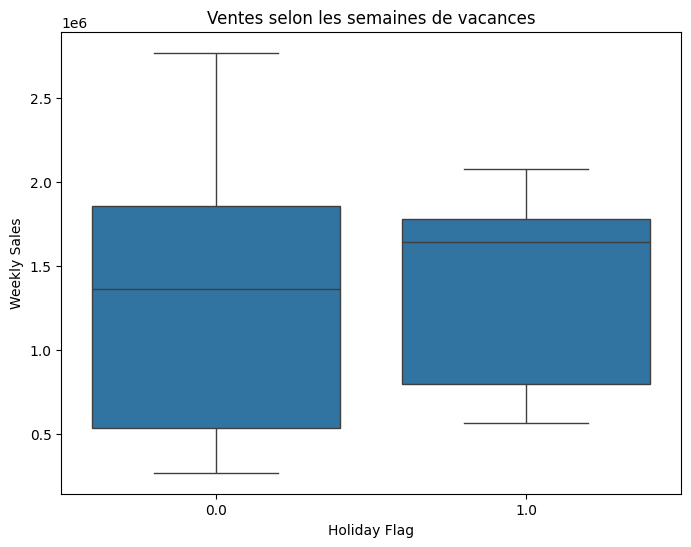

In [1011]:
# Visualisation des ventes selon les semaines de vacances

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Holiday_Flag', y='Weekly_Sales')
plt.title('Ventes selon les semaines de vacances')
plt.xlabel('Holiday Flag')
plt.ylabel('Weekly Sales')
plt.show()


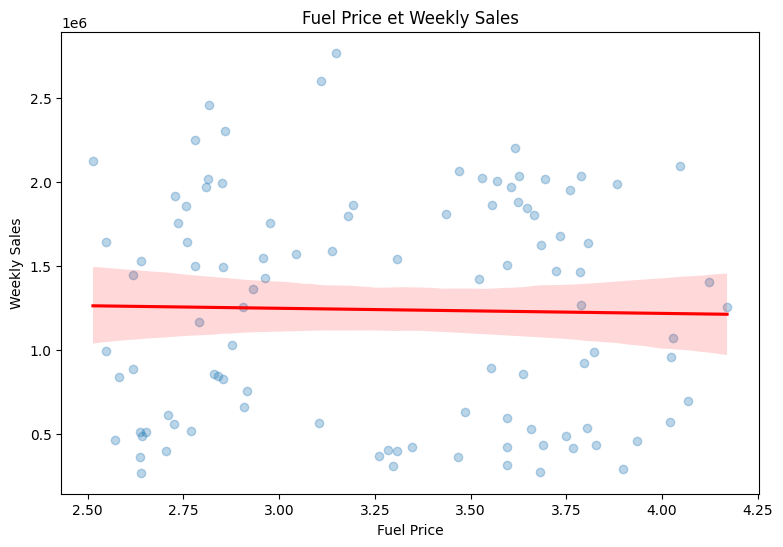

In [1012]:
# Visualisation des ventes selon le prix du carburant

plt.figure(figsize=(9,6))

sns.regplot(
    data=df,
    x="Fuel_Price",
    y="Weekly_Sales",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Fuel Price et Weekly Sales")
plt.xlabel("Fuel Price")
plt.ylabel("Weekly Sales")

plt.show()


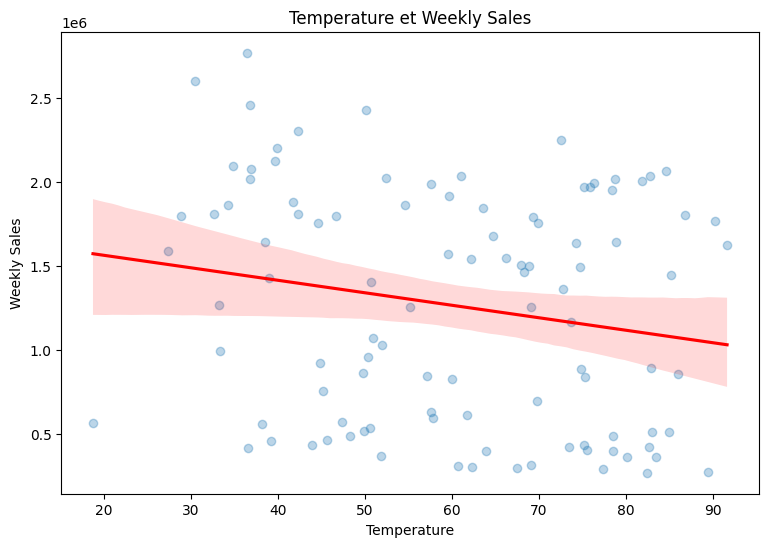

In [1013]:
# Visualisation des ventes selon la température

plt.figure(figsize=(9,6))

sns.regplot(
    data=df,
    x="Temperature",
    y="Weekly_Sales",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Temperature et Weekly Sales")
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")

plt.show()

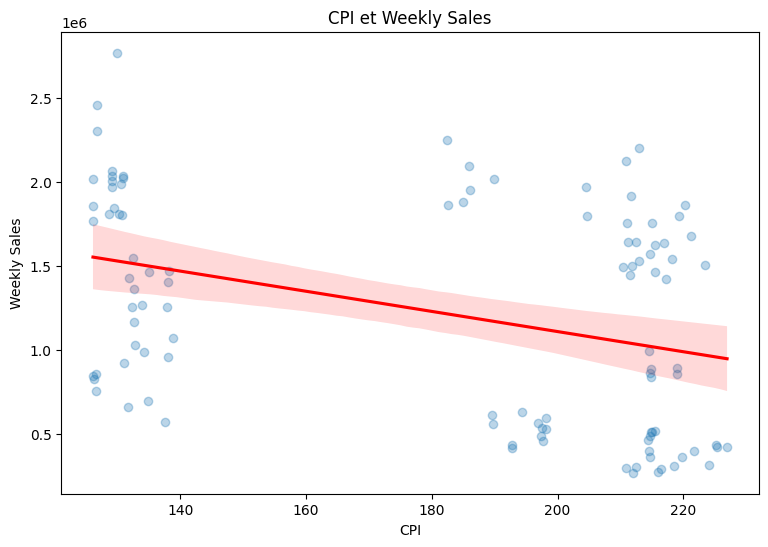

In [1014]:
# Visualisation des ventes selon le CPI

plt.figure(figsize=(9,6))

sns.regplot(
    data=df,
    x="CPI",
    y="Weekly_Sales",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("CPI et Weekly Sales")
plt.xlabel("CPI")
plt.ylabel("Weekly Sales")

plt.show()

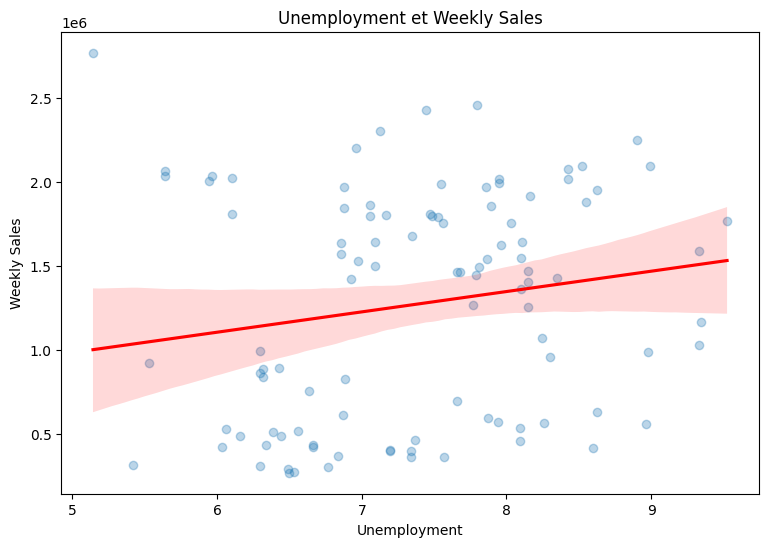

In [1015]:
# Visualisation des ventes selon unemployment

plt.figure(figsize=(9,6))

sns.regplot(
    data=df,
    x="Unemployment",
    y="Weekly_Sales",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Unemployment et Weekly Sales")
plt.xlabel("Unemployment")
plt.ylabel("Weekly Sales")

plt.show()

# Analyse multivariée


<Axes: title={'center': 'Matrice de corrélation'}>

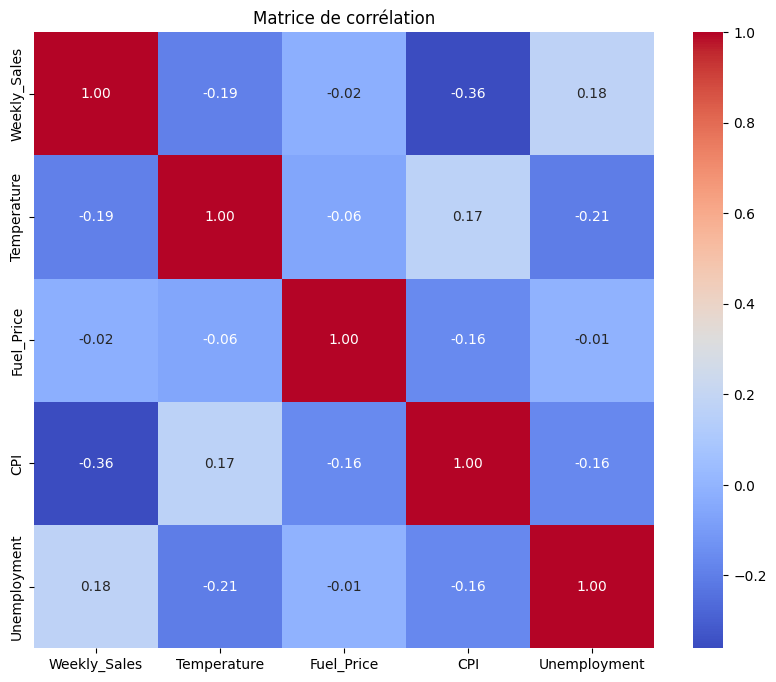

In [1016]:
# Visualisation de la matrice de corrélation entre les variables numériques

plt.figure(figsize=(10, 8))
correlation_matrix = df[['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']].corr()
plt.title('Matrice de corrélation')
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

In [1017]:
# Calcul des corrélations entre les ventes hebdomadaires et le chômage par magasin

correlations = (
    df.groupby("Store")
      .apply(lambda x: x["Unemployment"].corr(x["Weekly_Sales"]))
      .sort_values()
)

print(correlations)


Store
15.0   -1.000000
17.0   -0.808528
20.0   -0.612216
5.0    -0.523849
10.0   -0.509483
4.0    -0.507835
3.0    -0.343466
2.0    -0.081606
8.0    -0.081120
1.0    -0.054039
6.0    -0.037970
7.0     0.001302
19.0    0.108367
13.0    0.327136
9.0     0.371252
18.0    0.486914
14.0    0.497561
16.0    0.668510
11.0         NaN
dtype: float64


c:\Users\vavro\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:3015: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
c:\Users\vavro\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:2888: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
c:\Users\vavro\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\lib\_function_base_impl.py:2888: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


# Conclusion EDA

L’étude exploratoire des liens entre les variables explicatives et les ventes hebdomadaires met en évidence des comportements contrastés. Certaines variables semblent évoluer dans le même sens que les ventes, tandis que d’autres présentent une association négative ou peu marquée. Cette exploration a également permis d’identifier les mois les moins performants ainsi que les magasins enregistrant les niveaux de ventes les plus faibles, mettant ainsi en évidence des différences importantes selon la période et le magasin.

Pour le taux de chômage (Unemployment), la droite de régression est ascendante, indiquant qu’à l’échelle globale, les périodes caractérisées par un chômage plus élevé sont associées à des niveaux de ventes légèrement supérieurs. Cette tendance est cohérente avec la matrice de corrélation, qui affiche un coefficient de +0,18, correspondant à une association positive mais faible. Le taux de chômage semble ainsi avoir un rôle limité dans l’explication des variations des ventes et ne constitue pas un facteur déterminant à lui seul.

L’étude des ventes selon le statut de jour férié (Holiday_Flag) révèle également des niveaux globalement plus élevés durant les périodes identifiées comme des vacances ou jours fériés. Ces périodes semblent donc favoriser l’activité commerciale chez Walmart. Cette observation doit néanmoins être nuancée, puisque les performances peuvent également dépendre du magasin concerné, de la saisonnalité ou encore du contexte économique.

Concernant le prix du carburant (Fuel_Price), la droite de régression est quasiment horizontale, traduisant une association linéaire très faible avec les ventes hebdomadaires. Pris isolément, cet indicateur semble donc apporter peu d’éléments pour expliquer leurs fluctuations.

Le CPI se distingue par une association négative modérée avec les ventes : lorsque l’indice des prix à la consommation augmente, celles-ci ont tendance à diminuer. Toutefois, l’intensité de cette relation reste insuffisante pour considérer le CPI comme un facteur explicatif majeur pris individuellement.

Dans l’ensemble, ces résultats montrent qu’aucune des variables étudiées ne permet, à elle seule, d’expliquer pleinement les fluctuations des ventes hebdomadaires. Cette première exploration justifie donc le recours à un modèle multivarié, capable de prendre simultanément en compte les caractéristiques des magasins, les facteurs économiques, les conditions météorologiques ainsi que les effets temporels. La régression linéaire permettra ainsi d’évaluer la contribution respective de ces différents facteurs et leur capacité collective à expliquer les variations des ventes.

# Machine learning

In [1018]:
# Séparation des variables X de la variable cible Y

target_name = "Weekly_Sales"

Y = df.loc[:, target_name]
X = df.drop(target_name, axis=1)

print("La variable cible Y:")
print(Y.head())
print()
print("Les variables X:")
print(X.head())

La variable cible Y:
0    1641957.44
1    1494251.50
2    1449142.92
3    1466046.67
4    1624383.75
Name: Weekly_Sales, dtype: float64

Les variables X:
   Store       Date  Holiday_Flag  Temperature  Fuel_Price         CPI  \
0    1.0 2010-02-12           1.0        38.51       2.548  211.242170   
1    1.0 2010-05-14           0.0        74.78       2.854  210.337426   
2    1.0 2010-08-27           NaN        85.22       2.619  211.567306   
3    1.0 2011-05-27           0.0          NaN       3.786  215.503788   
4    1.0 2011-08-05           NaN        91.65       3.684  215.544618   

   Unemployment   Day  Month    Year  Day_of_Week  date_diff  
0         8.106  12.0    2.0  2010.0          4.0        NaN  
1         7.808  14.0    5.0  2010.0          4.0       91.0  
2         7.787  27.0    8.0  2010.0          4.0      105.0  
3         7.682  27.0    5.0  2011.0          4.0      273.0  
4         7.962   5.0    8.0  2011.0          4.0       70.0  


In [1019]:
# Séparation du train et du test

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

print("Séparation des données en train et test :")
print(f"Train : {X_train.shape[0]} échantillons")
print(f"Test : {X_test.shape[0]} échantillons")

Séparation des données en train et test :
Train : 90 échantillons
Test : 23 échantillons


In [1020]:
# Préparation des variables X
# Standardisation des variables numériques et encodage des variables catégorielles

#Définition des variables numériques

numeric_features = ['Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Day', 'Month', 'Year']

#Création d'un pipeline de transformation pour les variables numériques
#(standardisation et imputation des valeurs manquantes)

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
             SimpleImputer(strategy="median"),
         ),
        
        ("scaler", StandardScaler()),
    ]
)

#Définition des variables catégorielles

categorical_features = ['Store', 'Holiday_Flag']

#Création d'un pipeline de transformation pour les variables catégorielles
#(encodage et imputation des valeurs manquantes)

categorical_transformer = Pipeline(
    steps=[
        ("imputer",
         SimpleImputer(strategy="most_frequent"),
         ),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"),
        ),
    ]
)

#Application des transformations sur les variables numériques et catégorielles

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

#Application du préprocesseur sur les données d'entraînement et de test

# Train set : fit_transform apprend les paramètres de transformation sur X_train et applique ensuite les transformations sur X_train

print("Performing preprocessings on train set...")
X_train = preprocessor.fit_transform(X_train)
print("...Done.")
print(
    X_train[0:5]
) 
print()

feature_names = preprocessor.get_feature_names_out()

# Test set : transform applique les transformations apprises sur X_train à X_test

print("Performing preprocessings on test set...")
X_test = preprocessor.transform(
    X_test
) 
print("...Done.")

# Affichage des 5 premières lignes de X_test après transformation

print(
    X_test[0:5, :]
) 
print()

Performing preprocessings on train set...
...Done.
[[ 1.2295641  -1.31853055  0.77694811 -0.9602549   1.60190622  0.22824042
  -0.92295821  0.          0.          0.          1.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.        ]
 [-1.18608878  0.40317509 -1.43907184  0.10239826  0.98314416 -1.1187522
   0.28090032  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          1.
   0.          0.          0.          0.          0.          0.
   0.          0.        ]
 [ 0.44061958  0.02634895  0.4022911   0.16458638  0.85939175  0.90173673
  -0.92295821  0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   0.          0.          0.          0.          0.          0.
   1.          0.        ]
 [-0.68101964  1.89531998 -1.1885818   0.84429163 -1.

In [1021]:
# Entraînement du modèle de régression linéaire sur les données d'entraînement

# Train model
print("Train model...")
regressor = LinearRegression()
regressor.fit(X_train, Y_train)
print("...Done.")

# Prédictions sur l'ensemble d'entraînement

print("Predictions on training set...")
Y_train_pred_regression = regressor.predict(X_train)
print("...Done.")
print(Y_train_pred_regression)
print()

# Prédictions sur l'ensemble de test

print("Predictions on test set...")
Y_test_pred_regression = regressor.predict(X_test)
print("...Done.")
print(Y_test_pred_regression)
print()


Train model...
...Done.
Predictions on training set...
...Done.
[ 301377.64078075 1852190.52138065 1943557.65876692 1419585.54834539
  381043.96174008  484389.98243829 1366816.38729288 2018905.49426412
  435684.71975606  169766.9191875  1396379.24191669 1996334.06633229
  252197.55922315 1943948.93087115 2164986.89226985 2132611.24669456
 1564386.29739935 1579160.88944956  850654.9314571  1916343.62281969
 1607077.51850859  444302.62787907  376246.49782027 1153346.51682592
  196945.80429593  498214.0506938  1581885.8065568   576223.7821899
 1914156.68415887  565075.44674834 2198824.4747051   444847.90233142
  791487.67404825 1117075.60329377 2273705.38622483 2005995.89204504
  573130.21516244  569169.07572093 1900737.02162268 1989622.18247396
 2020609.9178146  1434638.44666126  311479.07339182 1535459.83234252
  926236.53232967 1504552.9088022  2069778.54689884 1471248.41094358
  833246.69808494  785238.34507291 1002856.38810977 2207161.48009488
  584113.25616929 2007874.54487718 19335

In [1022]:
# Évaluation du modèle de régression linéaire

r2_train_regression = r2_score(Y_train, Y_train_pred_regression)
r2_test_regression = r2_score(Y_test, Y_test_pred_regression)

print(f"R2 score on training set: {r2_train_regression:.4f}")
print(f"R2 score on test set: {r2_test_regression:.4f}")

R2 score on training set: 0.9789
R2 score on test set: 0.9259


In [1023]:
# Calcul des coefficients du modèle de régression linéaire et affichage des variables les plus importantes

coefficients = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient": regressor.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(coefficients)



                 Variable   Coefficient
10         cat__Store_5.0 -1.300368e+06
8          cat__Store_3.0 -1.201320e+06
14         cat__Store_9.0 -1.162192e+06
20        cat__Store_16.0 -1.034275e+06
12         cat__Store_7.0 -8.975242e+05
9          cat__Store_4.0  8.846176e+05
15        cat__Store_10.0  7.752828e+05
13         cat__Store_8.0 -7.458940e+05
18        cat__Store_14.0  7.228724e+05
17        cat__Store_13.0  7.012900e+05
19        cat__Store_15.0 -5.366003e+05
21        cat__Store_17.0 -4.760468e+05
24        cat__Store_20.0  4.722230e+05
7          cat__Store_2.0  3.773553e+05
23        cat__Store_19.0  2.742396e+05
16        cat__Store_11.0  1.765259e+05
2                num__CPI  1.609675e+05
3       num__Unemployment -7.704485e+04
1         num__Fuel_Price -4.384645e+04
0        num__Temperature -3.880357e+04
4                num__Day -3.201478e+04
5              num__Month  3.139250e+04
25  cat__Holiday_Flag_1.0 -2.316250e+04
22        cat__Store_18.0 -1.763488e+04


In [1024]:
# Conversion des coefficients en valeurs absolues et tri par ordre décroissant

feature_importance = pd.Series(
    np.abs(regressor.coef_),
    index=feature_names
).sort_values(ascending=False)

feature_importance
feature_importance


cat__Store_5.0           1.300368e+06
cat__Store_3.0           1.201320e+06
cat__Store_9.0           1.162192e+06
cat__Store_16.0          1.034275e+06
cat__Store_7.0           8.975242e+05
cat__Store_4.0           8.846176e+05
cat__Store_10.0          7.752828e+05
cat__Store_8.0           7.458940e+05
cat__Store_14.0          7.228724e+05
cat__Store_13.0          7.012900e+05
cat__Store_15.0          5.366003e+05
cat__Store_17.0          4.760468e+05
cat__Store_20.0          4.722230e+05
cat__Store_2.0           3.773553e+05
cat__Store_19.0          2.742396e+05
cat__Store_11.0          1.765259e+05
num__CPI                 1.609675e+05
num__Unemployment        7.704485e+04
num__Fuel_Price          4.384645e+04
num__Temperature         3.880357e+04
num__Day                 3.201478e+04
num__Month               3.139250e+04
cat__Holiday_Flag_1.0    2.316250e+04
cat__Store_18.0          1.763488e+04
num__Year                6.674596e+03
cat__Store_6.0           2.098369e+03
dtype: float

La variable Store apparaît comme le principal facteur associé aux différences de ventes hebdomadaires. Les coefficients des différents magasins présentent des valeurs importantes, traduisant des écarts structurels marqués dans les niveaux de ventes selon les magasins. Cela confirme que les caractéristiques propres à chaque magasin jouent un rôle prépondérant dans les performances commerciales.

Parmi les variables numériques standardisées, le CPI présente le coefficient positif le plus élevé, suggérant qu’une augmentation du CPI est associée à une hausse des ventes.

In [1025]:
# Ridge

alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge = RidgeCV(
    alphas=alphas,
    cv=5
)

# Entraînement du modèle Ridge sur les données d'entraînement

ridge.fit(X_train, Y_train)

# Prédictions sur l'ensemble d'entraînement avec le modèle Ridge

Y_train_pred_ridge = ridge.predict(X_train)

# Prédictions sur l'ensemble de test avec le modèle Ridge

Y_test_pred_ridge = ridge.predict(X_test)

# Meilleur alpha trouvé par RidgeCV

print("Meilleur alpha :", ridge.alpha_)



Meilleur alpha : 0.01


In [1026]:
# Lasso

lasso = LassoCV(
    alphas=[0.01, 0.1, 1, 10, 100],
    cv=5,
    max_iter=10000
)

# Entraînement du modèle Lasso

lasso.fit(X_train, Y_train)

# Prédictions sur l'ensemble d'entraînement avec le modèle Lasso

Y_train_pred_lasso = lasso.predict(X_train)

# Prédictions sur l'ensemble de test avec le modèle Lasso

Y_test_pred_lasso = lasso.predict(X_test)

# Meilleur alpha trouvé par LassoCV

print("Meilleur alpha :", lasso.alpha_)


Meilleur alpha : 100.0


In [1027]:
# Evaluation des modèles Régression, Ridge et Lasso avec le R2 score

# Régression linéaire

r2_train_regression = r2_score(Y_train, Y_train_pred_regression)
r2_test_regression = r2_score(Y_test, Y_test_pred_regression)

# Ridge

r2_train_ridge = r2_score(Y_train, Y_train_pred_ridge)
r2_test_ridge = r2_score(Y_test, Y_test_pred_ridge)

# Lasso

r2_train_lasso = r2_score(Y_train, Y_train_pred_lasso)
r2_test_lasso = r2_score(Y_test, Y_test_pred_lasso)

# Affichage des résultats

results_r2 = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso"
    ],
    "R² Train": [
        r2_train_regression,
        r2_train_ridge,
        r2_train_lasso
    ],
    "R² Test": [
        r2_test_regression,
        r2_test_ridge,
        r2_test_lasso
    ]
})

results_r2["Train-Test Gap"] = (
    results_r2["R² Train"] - results_r2["R² Test"]
)

print(results_r2.round(4))



               Model  R² Train  R² Test  Train-Test Gap
0  Linear Regression    0.9789   0.9259          0.0530
1              Ridge    0.9789   0.9267          0.0521
2              Lasso    0.9789   0.9265          0.0523


Les modèles régularisés Ridge et Lasso apportent une légère amélioration par rapport à la régression linéaire classique. Le modèle Ridge obtient les meilleures performances, avec un R² de 92,67 % sur l’ensemble de test, contre 92,59 % pour la régression linéaire et 92,65 % pour le Lasso. Il apparaît ainsi comme le modèle le plus performant parmi les trois, bien que les écarts de performance restent relativement faibles.

In [1028]:
# Calcul des coefficients du modèle Lasso

coefficients = pd.DataFrame({
    "Variable": feature_names,
    "Coefficient": ridge.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print(coefficients)

                 Variable   Coefficient
10         cat__Store_5.0 -1.289810e+06
8          cat__Store_3.0 -1.192844e+06
14         cat__Store_9.0 -1.150252e+06
20        cat__Store_16.0 -1.027086e+06
12         cat__Store_7.0 -8.968793e+05
9          cat__Store_4.0  8.769469e+05
15        cat__Store_10.0  7.618432e+05
13         cat__Store_8.0 -7.347148e+05
18        cat__Store_14.0  7.209006e+05
17        cat__Store_13.0  6.939766e+05
19        cat__Store_15.0 -5.419946e+05
21        cat__Store_17.0 -4.818859e+05
24        cat__Store_20.0  4.749983e+05
7          cat__Store_2.0  3.815252e+05
23        cat__Store_19.0  2.638816e+05
16        cat__Store_11.0  1.808437e+05
2                num__CPI  1.545470e+05
3       num__Unemployment -7.429209e+04
1         num__Fuel_Price -4.410853e+04
0        num__Temperature -3.917356e+04
5              num__Month  3.213268e+04
4                num__Day -3.179715e+04
22        cat__Store_18.0 -2.780132e+04
25  cat__Holiday_Flag_1.0 -2.401443e+04


In [1029]:
# Conversion des coefficients en valeurs absolues et tri par ordre décroissant

feature_importance = pd.Series(
    np.abs(ridge.coef_),
    index=feature_names
).sort_values(ascending=False)

feature_importance
feature_importance

cat__Store_5.0           1.289810e+06
cat__Store_3.0           1.192844e+06
cat__Store_9.0           1.150252e+06
cat__Store_16.0          1.027086e+06
cat__Store_7.0           8.968793e+05
cat__Store_4.0           8.769469e+05
cat__Store_10.0          7.618432e+05
cat__Store_8.0           7.347148e+05
cat__Store_14.0          7.209006e+05
cat__Store_13.0          6.939766e+05
cat__Store_15.0          5.419946e+05
cat__Store_17.0          4.818859e+05
cat__Store_20.0          4.749983e+05
cat__Store_2.0           3.815252e+05
cat__Store_19.0          2.638816e+05
cat__Store_11.0          1.808437e+05
num__CPI                 1.545470e+05
num__Unemployment        7.429209e+04
num__Fuel_Price          4.410853e+04
num__Temperature         3.917356e+04
num__Month               3.213268e+04
num__Day                 3.179715e+04
cat__Store_18.0          2.780132e+04
cat__Holiday_Flag_1.0    2.401443e+04
cat__Store_6.0           5.554036e+03
num__Year                5.147122e+03
dtype: float

Le modèle Ridge produit des coefficients très proches de ceux de la régression linéaire classique. La régularisation entraîne une légère réduction de la magnitude des coefficients, mais ne modifie pas substantiellement la structure du modèle. Cette faible modification est cohérente avec l'absence d'amélioration significative des performances du modèle sur l'ensemble de test.

In [1030]:
# Calcul des MAE et RMSE pour les modèles Régression, Ridge et Lasso

# Régression linéaire

mae_regression = mean_absolute_error(Y_test, Y_test_pred_regression)
rmse_regression = np.sqrt(mean_squared_error(Y_test, Y_test_pred_regression))

print("Linear Regression")
print("MAE :", mae_regression)
print("RMSE:", rmse_regression)
print("Différence entre RMSE et MAE :", rmse_regression - mae_regression)

# Lasso
mae_lasso = mean_absolute_error(Y_test, Y_test_pred_lasso)
rmse_lasso = np.sqrt(
    mean_squared_error(Y_test, Y_test_pred_lasso)
)

print("\nLasso")
print("MAE :", mae_lasso)
print("RMSE:", rmse_lasso)
print("Différence entre RMSE et MAE :", rmse_lasso - mae_lasso)

mae_ridge = mean_absolute_error(Y_test, Y_test_pred_ridge)
rmse_ridge = np.sqrt(
    mean_squared_error(Y_test, Y_test_pred_ridge)
)

print("\nRidge")
print("MAE :", mae_ridge)
print("RMSE:", rmse_ridge)
print("Différence entre RMSE et MAE :", rmse_ridge - mae_ridge)

Linear Regression
MAE : 131254.74176660282
RMSE: 176718.880877478
Différence entre RMSE et MAE : 45464.13911087517

Lasso
MAE : 130435.77472890764
RMSE: 176001.49512808348
Différence entre RMSE et MAE : 45565.72039917584

Ridge
MAE : 130908.6216740171
RMSE: 175749.28274221704
Différence entre RMSE et MAE : 44840.661068199945


L'analyse des erreurs de prédiction confirme les performances relativement proches des trois modèles. Le modèle Ridge obtient le RMSE le plus faible (175 749), tandis que le Lasso présente le MAE le plus faible (130 436). La régression linéaire affiche les erreurs les plus élevées sur ces deux indicateurs. Les écarts entre les modèles restent toutefois limités. En combinant ces résultats avec le R² obtenu sur l'ensemble de test, le modèle Ridge apparaît comme le meilleur compromis, avec un R² de 92,67 % et le RMSE le plus faible. Le Lasso reste néanmoins très proche en termes de performance.

In [ ]:
# Création d'une fonction pour prédire les ventes hebdomadaires

def predict_weekly_sales(Store, Holiday_flag, Unemployment, Cpi, Month, Temperature, Fuel_price, Day, Year):
    """
    Prédit les ventes hebdomadaires pour un magasin donné à partir des données d'entrée.
    
    Args:
        Store (int): Numéro du magasin.
        Holiday_flag (int): Indicateur de jour férié.
        Unemployment (float): Taux de chômage.
        Cpi (float): Indice du coût de la vie.
        Month (int): Mois.
        Temperature (float): Température.
        Fuel_price (float): Prix du carburant.
        Day (int): Jour.
        Year (int): Année. 
        
    Returns:
        float: Prédiction des ventes hebdomadaires.
        
    """
    new_observation = pd.DataFrame([{
        "Store": Store,
        "Holiday_Flag": Holiday_flag,
        "Unemployment": Unemployment,
        "CPI": Cpi,
        "Month": Month,
        "Temperature": Temperature,
        "Fuel_Price": Fuel_price,
        "Day": Day,
        "Year": Year
    }])

    input_transformed = preprocessor.transform(new_observation)
    prediction = ridge.predict(input_transformed)
    return prediction[0]

prediction = predict_weekly_sales(
    Store=16,
    Holiday_flag=0,
    Unemployment=5.0,
    Cpi=220.0,
    Month=6,
    Temperature=20.0,
    Fuel_price=3.0,
    Day=15,
    Year=2023
)

print(f"Prédiction des ventes : ${prediction:.2f}")



Prédiction des ventes : $800772.79


# Conclusion


En conclusion, l’analyse exploratoire des ventes hebdomadaires totales entre 2010 et 2012 révèle une forte volatilité des ventes. Aucune tendance générale clairement croissante ou décroissante n’est observée. Plusieurs pics importants sont néanmoins visibles, dont un maximum d’environ 7,3 millions de dollars vers la fin de l’année 2010. Les variables économiques semblent, à elles seules, relativement peu expliquer les variations des ventes, tandis que les caractéristiques temporelles et les spécificités propres aux magasins semblent jouer un rôle plus important.

L’analyse temporelle a permis d’identifier les mois présentant les ventes hebdomadaires moyennes les plus faibles, inférieures à 1 000 000 de dollars, notamment avril, septembre, octobre et novembre. L’analyse des performances par magasin a également permis d’identifier les magasins les moins performants, avec des ventes hebdomadaires moyennes inférieures à 500 000 dollars pour les magasins 3, 5, 9 et 16.

La régression linéaire confirme notamment l’importance de l’effet du magasin et met en évidence des coefficients relativement élevés pour le CPI, le taux de chômage et le prix du carburant parmi les variables numériques étudiées. Le modèle de régression linéaire obtient un R² de 92,59 % sur l’ensemble de test, indiquant qu’il explique une part importante de la variabilité des ventes. Les modèles régularisés présentent des performances très proches, mais Ridge obtient les meilleurs résultats, avec un R² test de 92,67 % et le RMSE le plus faible (175 749). Le Lasso obtient quant à lui le MAE le plus faible (130 436), mais l’écart avec Ridge reste limité. La régularisation Ridge semble donc apporter une légère amélioration par rapport à la régression linéaire classique, même si les différences de performance entre les trois modèles restent faibles. Le modèle Ridge est ainsi retenu comme modèle final, car il offre le meilleur compromis entre capacité explicative et précision des prédictions sur l’ensemble de test.

Ces résultats doivent toutefois être interprétés avec prudence. Le dataset reste relativement limité, avec moins de 150 observations réparties entre 20 magasins. Les écarts importants entre les magasins peuvent fortement influencer les niveaux de ventes et rendre certaines relations plus difficiles à interpréter. Par ailleurs, les données étant hebdomadaires et ne couvrant pas les mêmes périodes pour l’ensemble des magasins, certains mois ou certaines saisons sont sous-représentés. Les résultats obtenus ne peuvent donc pas nécessairement être généralisés à d’autres périodes ou à l’ensemble des magasins.

Cette étude permet néanmoins d’identifier plusieurs facteurs susceptibles d’être associés aux variations des ventes, notamment le CPI, le taux de chômage et les périodes de vacances. Ces résultats permettent également d’identifier les magasins les moins performants ainsi que les périodes de faible activité, et constituent ainsi des leviers intéressants pour orienter les actions marketing.

Afin d’approfondir cette analyse, il serait pertinent d’enrichir la base de données afin de disposer d’une couverture temporelle plus complète pour chaque magasin. Une analyse menée individuellement pour chaque point de vente permettrait également de mieux prendre en compte leurs spécificités. Des informations complémentaires telles que le type de produits vendus, le profil des clients ciblés, la localisation ou encore les performances par catégorie de produits permettraient de mieux comprendre les différences de performance entre les magasins.

Ces données pourraient ensuite être utilisées pour mettre en place des actions marketing plus ciblées. Par exemple, les périodes identifiées comme étant les moins performantes pourraient faire l’objet de promotions ou d’offres spécifiques afin de stimuler les ventes. Les magasins présentant les performances les plus faibles pourraient également bénéficier de campagnes locales adaptées à leur clientèle et à leur environnement. À l’inverse, pour les magasins les plus performants, des actions de fidélisation pourraient être mises en place afin de conserver les clients et d’augmenter leur fréquence d’achat ou leur panier moyen.

L’analyse de la saisonnalité permettrait également d’anticiper les variations de la demande et de planifier les campagnes marketing en amont. Les facteurs économiques tels que le CPI ou le taux de chômage pourraient, quant à eux, être intégrés à cette stratégie afin d’adapter les offres au contexte économique. Par exemple, lors de périodes où le pouvoir d’achat est davantage contraint, des promotions, des offres groupées ou des avantages fidélité pourraient être privilégiés.

Enfin, l’efficacité de ces actions pourrait être mesurée à partir des données de ventes afin d’identifier les campagnes générant réellement une amélioration des performances. Une comparaison des ventes avant et après une campagne, voire entre des magasins ayant bénéficié de l’action et des magasins similaires n’en ayant pas bénéficié, permettrait d’évaluer plus précisément son impact.

Ainsi, l’enrichissement des données permettrait de passer d’une analyse descriptive des ventes à une approche davantage prédictive et décisionnelle. L’objectif serait alors d’utiliser la Data non seulement pour mieux comprendre les variations du chiffre d’affaires, mais également pour anticiper les périodes à risque, personnaliser les actions marketing et mesurer leur efficacité en fonction des spécificités de chaque magasin.